In [1]:
from dlroms import*
import numpy as np
pi = np.pi

train_cpfn = False

def f(x, z, p):
    if(x<0.5 or p<0.5):
        return 10*x*(x-0.5)*(1.5-x) + z*0.3*(1.3-x)
    else:
        return 10*x*(x-0.5)*(0.8-x) + z*0.3*(1.3-x)

def true_sample(x):
    z = np.random.randn()
    p = np.random.rand()
    return f(x, z, p)

/home/u10738811/anaconda3/envs/dlroms/lib/python3.13/site-packages/dlroms/fespaces.py:48: UserWarning: Either dolfin or fenics are not available. Some functions might not be available or work as expected.
  warnings.warn("Either dolfin or fenics are not available. Some functions might not be available or work as expected.")


In [2]:
from generative import PushForward
from dlroms.dnns import Reshape

def MCrun(ntrain, seed):
    np.random.seed(seed)
    xs = np.random.rand(ntrain)
    ys = np.array([true_sample(x) for x in xs])
    xs, ys = dv.tensor(xs, ys)
    xs = xs.reshape(-1, 1)
    ys = ys.reshape(-1, 1)
    
    L, r = 50, 20
    d, q = xs.shape[1], ys.shape[1]
    phi = Dense(d, L, gelu) + Dense(L, L, gelu) + Dense(L, L, gelu) + Dense(L, r*q, None) + Reshape(r, q)
    psi = Dense(q, L, gelu) + Dense(L, L, gelu) + Dense(L, L, gelu) + Dense(L, r*q, gelu) + Reshape(r, q)
    cpfn = PushForward(phi, psi)
    cpfn.cuda()

    cpfn.fit(xs, ys, epochs = 3000, lr = 1e-3, m = 30, h0 = 5e-2, title = "%d samples, iteration %d..." % (ntrain, seed % 100))
    cpfn.save("trained/branched/branched%dntrain_%d" % (ntrain, seed % 100))

def MCload(ntrain, seed):
    L, r = 50, 20
    d, q = 1, 1
    phi = Dense(d, L, gelu) + Dense(L, L, gelu) + Dense(L, L, gelu) + Dense(L, r*q, None) + Reshape(r, q)
    psi = Dense(q, L, gelu) + Dense(L, L, gelu) + Dense(L, L, gelu) + Dense(L, r*q, gelu) + Reshape(r, q)
    cpfn = PushForward(phi, psi)
    cpfn.cuda()
    cpfn.load("trained/branched/branched%dntrain_%d" % (ntrain, seed % 100))
    cpfn.freeze()
    return cpfn

In [3]:
import os
files = os.listdir("trained")
mc = 100

if(train_cpfn):
    seed = 0
    for ntrain in [250, 500, 1000]:
        for j in range(mc):
            if(("branched%dntrain_%d.npz" % (ntrain, seed % 100)) not in files):
                cpfn = MCrun(ntrain, seed)
                clc()
            seed += 1

In [69]:
from scipy.stats import norm
from scipy.integrate import simpson

xgrid = np.linspace(0, 1, 101)
qgrid = np.linspace(0, 1, 101)[1:-1]

Q = np.load("testcases/branched/qs_true.npy") #np.array([[np.quantile([sample(x) for i in range(1000)], alpha) for alpha in qgrid] for x in xgrid])

def fastl1l1q_error(cpfn):
  def fastqerror(k):
    yg = cpfn.sample(dv.tensor(xgrid[k]), m = 1000)[0]
    qtrue = Q[k]
    qpred = yg.quantile(dv.tensor(qgrid)).detach().cpu().numpy()
    return simpson(np.abs(qtrue-qpred), dx = 1e-2)

  l1l1q = simpson(np.abs([fastqerror(k) for k in range(len(xgrid))]), dx = 1e-2)
  return l1l1q

In [5]:
print("ntrain\terror\tstd")
print("-"*20)
for ntrain in [250, 500, 1000]:
    errors = np.stack([fastl1l1q_error(MCload(ntrain, j)) for j in range(mc)])
    mean, std = errors.mean(), errors.std(ddof = 1)
    print("%d\t%.4f\t%.4f" % (ntrain, mean, std))

ntrain	error	std
--------------------
250	0.0799	0.0185
500	0.0603	0.0097
1000	0.0507	0.0084


In [6]:
def q_error(cpfn, q0):
  j = np.argmax(qgrid == q0)
  def fastqerror(k):
    yg = cpfn.sample(dv.tensor(xgrid[k]), m = 1000)[0]
    qtrue = Q[k]
    qpred = yg.quantile(dv.tensor(qgrid)).detach().cpu().numpy()
    return np.abs(qtrue-qpred)[j]

  l1l1q = simpson(np.abs([fastqerror(k) for k in range(len(xgrid))]), dx = 1e-2)
  return l1l1q

for q0 in [0.1, 0.25, 0.5, 0.75, 0.9]:
    print("q = %.2f" % q0)
    print("ntrain\terror\tstd")
    print("-"*20)
    for ntrain in [250, 500, 1000]:
        errors = np.stack([q_error(MCload(ntrain, j), q0) for j in range(mc)])
        mean, std = errors.mean(), errors.std(ddof = 1)
        print("%d\t%.4f\t%.4f" % (ntrain, mean, std))
    print("\n" + ("-"*20) + "\n")

q = 0.10
ntrain	error	std
--------------------
250	0.0625	0.0185
500	0.0480	0.0133
1000	0.0388	0.0091

--------------------

q = 0.25
ntrain	error	std
--------------------
250	0.0522	0.0150
500	0.0382	0.0086
1000	0.0304	0.0069

--------------------

q = 0.50
ntrain	error	std
--------------------
250	0.2850	0.0638
500	0.2566	0.0566
1000	0.2457	0.0524

--------------------

q = 0.75
ntrain	error	std
--------------------
250	0.0471	0.0146
500	0.0377	0.0098
1000	0.0299	0.0077

--------------------

q = 0.90
ntrain	error	std
--------------------
250	0.0604	0.0194
500	0.0458	0.0135
1000	0.0363	0.0102

--------------------



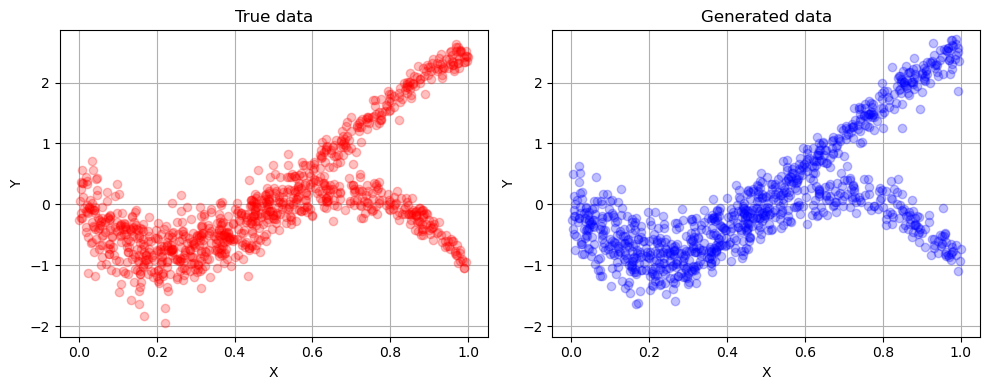

In [3]:
cpfn = MCload(1000, 0)

x = np.random.rand(1000)
y = [true_sample(x0) for x0 in x]
yg = cpfn.sample(x.reshape(-1, 1), m = 1).reshape(-1)

plt.figure(figsize = (10, 4))
plt.subplot(1,2,1)
plt.plot(x, y, 'or', alpha = 0.25)
plt.grid()
plt.ylabel("Y")
plt.xlabel("X")
plt.title("True data")
axis = plt.gca().axis()

plt.subplot(1,2,2)
plt.plot(x, yg, 'ob', alpha = 0.25)
plt.grid()
plt.ylabel("Y")
plt.xlabel("X")
plt.title("Generated data")
plt.axis(axis)
plt.tight_layout()
None

In [79]:
import seaborn as sb
from scipy.stats import norm

cpfn = MCload(1000, 9) # 9 (0.4, 0.75) -- 16 (0.4, 0.8) --- 20 (0.2, 0.8)

e1 = lambda x: 10*x*(x-0.5)*(1.5-x)
e2 = lambda x: 10*x*(x-0.5)*(0.8-x)
sigma = lambda x: abs(0.3*(1.3-x))

def density(y, x):
    if(x<0.5):
        return norm.pdf((y-e1(x))/sigma(x))/sigma(x)
    else:
        return (0.5*(norm.pdf((y-e1(x))/sigma(x)) + norm.pdf((y-e2(x))/sigma(x))))/sigma(x)

def conditional(x0):
    yrange = np.linspace(-4, 4, 1000)
    ydensity = [density(y, x0) for y in yrange]
    plt.plot(yrange, ydensity)
    plt.fill(yrange, ydensity, alpha = 0.5, label = "True density")
    
    ygx0 = cpfn.sample(dv.tensor(x0).reshape(1, 1), m = 100000).cpu().numpy().reshape(-1)
    sb.kdeplot(ygx0, fill = True, label = 'Generated data\ndistribution')
    plt.xlabel("y")
    plt.ylabel("Density", labelpad = -40)
    plt.gca().yaxis.label.set_position((2, 0.15))
    plt.title("Conditional at $x_0=$%.2f" % x0)
    plt.legend()

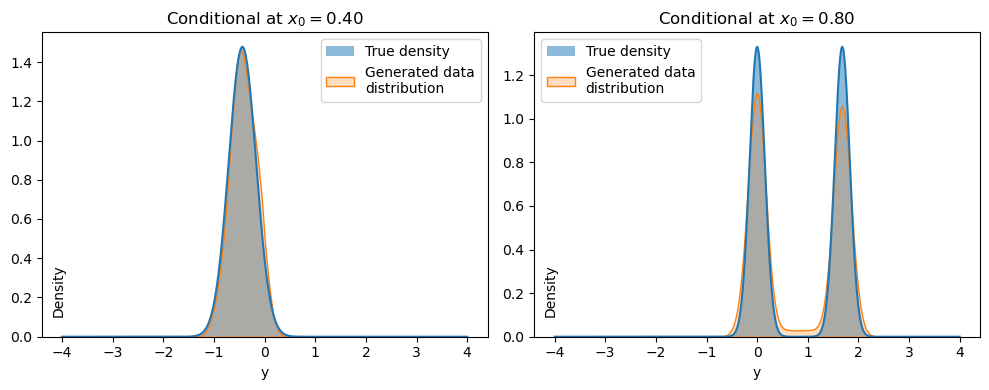

In [81]:
plt.figure(figsize = (10, 4))
plt.subplot(1,2,1)
conditional(0.4)
plt.subplot(1,2,2)
conditional(0.8)
plt.tight_layout()

In [70]:
Q.shape

(101, 99)

In [75]:
def cdf(y, x):
    if(x<0.5):
        return norm.cdf(y, loc = e1(x), scale = sigma(x))
    else:
        return 0.5*(norm.cdf(y, loc = e1(x), scale = sigma(x)) + norm.cdf(y, loc = e1(x), scale = sigma(x)))

In [77]:
i, j = 47, 83
cdf(Q[i,j], xgrid[i]), qgrid[j]

(np.float64(0.8407886914053826), np.float64(0.84))